# THINGS-EEG2 — full EDA (all 10 subjects, 17 ch and 63 ch)

**Goal:** check *every* subject (not only sub-01) and collect the numbers needed to decide
(a) 17 vs 63 channels, (b) how to split train / validation / test (within-subject and leave-one-subject-out).

**How to run on Colab**
1. Runtime -> Change runtime type. A CPU runtime is enough. If it crashes with "out of RAM" in section 5, switch on *High-RAM* or set `RUN_63CH_TRAIN = False`.
2. The data repo is private. Add a Colab *Secret* named `HF_TOKEN` (key icon on the left, tick "Notebook access") with a Hugging Face token that has **read** access to the repo. Otherwise the notebook will ask for the token.
3. Run all cells. It takes roughly 30-60 min (mostly downloads), and deletes each file after use to save disk.
4. The last cell prints a compact summary and downloads `eda_out.zip`. Send both back.

Metrics used (all are *signal-quality* measures, not model accuracy):
- **split-half r:** the 80 test repetitions of each image are split into even/odd halves and averaged; Pearson r between the two halves across the 200 images, per channel and time point, averaged over 50-500 ms.
- **identification top-1/top-5:** for each of the 200 test images, correlate its half-A response with all 200 half-B responses (after removing the mean over images) and check whether the correct one ranks first / in the top 5. Chance = 0.5% / 2.5%. No training involved.

## Data-leakage note (read this first)
**Rule from the proposal:** the 200 test images are used only for the final evaluation.

Many diagnostics below use the **test EEG** because it is the only set with 80 repetitions per image (high signal-to-noise ratio). That is fine for *describing* the data, but a finding that came from the test EEG must **not be used to choose model design** (channels, time window, frequency band, pilot subjects, thresholds). Choosing design by test numbers would be test-set model selection, i.e. a mild form of leakage that inflates the final test accuracy.

Every conclusion cell below is tagged:
- **[TRAIN]**: derived from training data only. Safe to base decisions on.
- **[TEST]**: derived from test EEG. Descriptive only. Treat as a hypothesis and re-check on training / validation data before using it for a decision.
- **[IMAGES]**: image files only, no EEG. No leakage concern.

Design decisions that currently rest on **[TEST]** evidence only (to be re-derived on training / validation): occipital-only vs 17 channels vs 17+TP, the exact time window, any frequency filtering, and the choice of pilot subjects.

In [14]:
import os, sys, json, time, gc, zipfile, pickle, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from scipy.stats import spearmanr, ks_2samp
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'huggingface_hub'], check=False)

# ------------------------------ config ------------------------------
REPO_ID = 'things-eeg2/things-eeg2-preprocessed'
LOCAL_ROOT = os.environ.get('EDA_LOCAL_ROOT')            # None on Colab -> download from the Hub
WORK = os.environ.get('EDA_WORK', '/content/work')       # scratch dir
RUN_63CH_TRAIN = os.environ.get('EDA_63CH_TRAIN', '1') == '1'   # 3.4 GB per subject in RAM; set False if you run out of memory
OUT = os.path.join(WORK, 'eda_out'); os.makedirs(OUT, exist_ok=True)
SUBJECTS = [f'sub-{i:02d}' for i in range(1, 11)]
TS = np.arange(100) * 0.01 - 0.2                         # -0.20 ... 0.79 s, stimulus onset at 0
WIN = (TS >= 0.05) & (TS <= 0.5)                         # analysis window 50-500 ms
t0 = time.time()
def log(*a): print(f'[{time.time()-t0:6.0f}s]', *a, flush=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(OUT, name), dpi=110); plt.show()

In [20]:
if not LOCAL_ROOT:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get('hf_token')
    except Exception:
        HF_TOKEN = os.environ.get('hf_token')
    if not HF_TOKEN:
        from getpass import getpass
        HF_TOKEN = getpass('Hugging Face token (read access): ')
    from huggingface_hub import hf_hub_download

def get_file(rel):
    """rel = path inside the repo, e.g. 'eeg/17ch/sub-01/preprocessed_eeg_test.npy'"""
    if LOCAL_ROOT:
        return os.path.join(LOCAL_ROOT, rel)
    return hf_hub_download(REPO_ID, rel, repo_type='dataset', token=HF_TOKEN, local_dir=WORK)

def release(path):
    if not LOCAL_ROOT and os.path.exists(path):
        os.remove(path)

# ------------------------------ safe loader for the pickled-dict .npy files ------------------------------
_OK = {('numpy', 'ndarray'), ('numpy', 'dtype'),
       ('numpy.core.multiarray', '_reconstruct'), ('numpy._core.multiarray', '_reconstruct'),
       ('numpy.core.multiarray', 'scalar'), ('numpy._core.multiarray', 'scalar'),
       ('builtins', 'dict'), ('builtins', 'list')}
class _U(pickle.Unpickler):
    def find_class(self, module, name):
        if (module, name) in _OK:
            return getattr(__import__(module, fromlist=[name]), name)
        raise pickle.UnpicklingError(f'blocked {module}.{name}')

def safe_load(path):
    obj = np.load(path, allow_pickle=True)
    return obj.item() if isinstance(obj, np.ndarray) and obj.shape == () else obj

# ------------------------------ metrics ------------------------------
def splithalf(A, B):
    """A, B: (n_img, ch, time). Pearson r across images for every (ch, time)."""
    A = A - A.mean(0); B = B - B.mean(0)
    return (A * B).sum(0) / (np.sqrt((A**2).sum(0) * (B**2).sum(0)) + 1e-12)

def _norm_rows(F):
    F = F - F.mean(1, keepdims=True)
    return F / (np.linalg.norm(F, axis=1, keepdims=True) + 1e-12)

def ident_acc(A, B, ch_idx=None):
    """Retrieve every image of A among all images of B (correlation, mean over images removed). Returns top1, top5."""
    if ch_idx is not None:
        A = A[:, ch_idx]; B = B[:, ch_idx]
    A = (A - A.mean(0))[:, :, WIN].reshape(len(A), -1)
    B = (B - B.mean(0))[:, :, WIN].reshape(len(B), -1)
    C = _norm_rows(A) @ _norm_rows(B).T
    order = np.argsort(-C, axis=1)[:, :5]
    gt = np.arange(len(A))[:, None]
    return float((order[:, :1] == gt).mean()), float((order == gt).any(1).mean())

def sym_ident(A, B, ch_idx=None):
    a = ident_acc(A, B, ch_idx); b = ident_acc(B, A, ch_idx)
    return (a[0] + b[0]) / 2, (a[1] + b[1]) / 2

def train_stats(Y, chunk=1000):
    """Memory-friendly global / per-channel stats of a (n, rep, ch, t) array."""
    n, _, C, _ = Y.shape
    s1 = np.zeros(C); s2 = np.zeros(C); big = np.zeros(C); cnt = 0
    nan = 0; mn = np.inf; mx = -np.inf; t5 = 0; t10 = 0
    for i in range(0, n, chunk):
        c = Y[i:i + chunk]
        nan += int(np.isnan(c).sum()); mn = min(mn, float(c.min())); mx = max(mx, float(c.max()))
        s1 += c.sum((0, 1, 3)); s2 += (c.astype(np.float64) ** 2).sum((0, 1, 3))
        big += (np.abs(c) > 5).sum((0, 1, 3)); cnt += c.shape[0] * c.shape[1] * c.shape[3]
        am = np.abs(c).max((2, 3)); t5 += int((am > 5).sum()); t10 += int((am > 10).sum())
    mean_c = s1 / cnt; std_c = np.sqrt(np.maximum(s2 / cnt - mean_c**2, 0))
    ntr = n * Y.shape[1]
    return dict(nan=nan, min=mn, max=mx, mean=float(mean_c.mean()), std=float(np.sqrt((s2.sum() / cnt / C) - mean_c.mean()**2)),
                ch_std=std_c, ch_frac_gt5=big / cnt, frac_trials_gt5=t5 / ntr, frac_trials_gt10=t10 / ntr)
log('setup ok; local mode =', bool(LOCAL_ROOT))

[    97s] setup ok; local mode = False


## 1. Images
Counts, sizes, concept overlap between train and test, a few examples, and whether train and test images differ in simple statistics (brightness / contrast).

{
 "n_train": 16540,
 "n_test": 200,
 "n_train_concepts": 1654,
 "n_test_concepts": 200,
 "imgs_per_concept": {
  "10": 1654
 },
 "test_concepts_in_train": 0,
 "train_sorted_by_concept": true,
 "missing": 0,
 "sizes": {
  "(500, 500, 'RGB')": 16740
 }
}


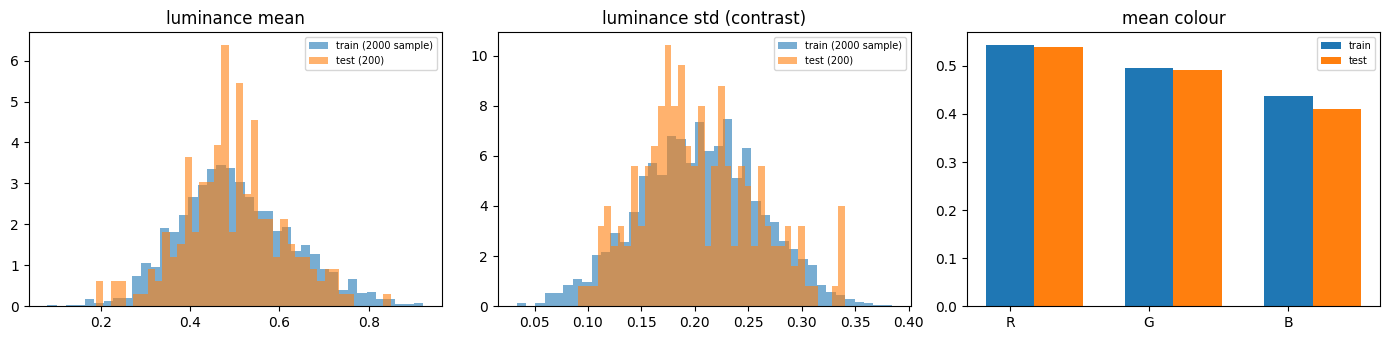

KS p-values train vs test (lum mean / std): 0.3395464419278025 0.36565160682291015


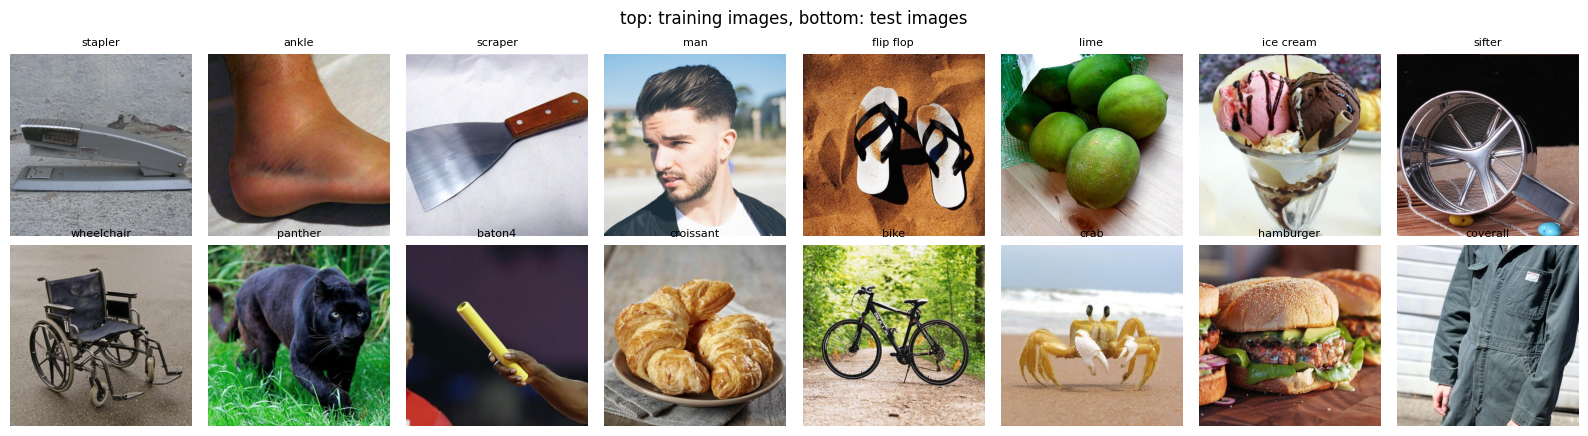

In [21]:
from PIL import Image
for f in ['training_images.zip', 'test_images.zip', 'image_metadata.npy']:
    p = get_file(f'images/{f}')
    if f.endswith('.zip'):
        d = os.path.join(WORK, 'images')
        if not os.path.isdir(os.path.join(d, f.replace('.zip', ''))):
            zipfile.ZipFile(p).extractall(d)
    else:
        META_PATH = p
meta = safe_load(META_PATH)
IMG = os.path.join(WORK, 'images')
tr_files, tr_conc = meta['train_img_files'], meta['train_img_concepts']
te_files, te_conc = meta['test_img_files'], meta['test_img_concepts']
tr_paths = [os.path.join(IMG, 'training_images', c, f) for c, f in zip(tr_conc, tr_files)]
te_paths = [os.path.join(IMG, 'test_images', c, f) for c, f in zip(te_conc, te_files)]
RES = {}
cnt = Counter(tr_conc)
RES['images'] = dict(n_train=len(tr_files), n_test=len(te_files), n_train_concepts=len(cnt), n_test_concepts=len(set(te_conc)),
                     imgs_per_concept=dict(Counter(cnt.values())),
                     test_concepts_in_train=len(set(meta['test_img_concepts_THINGS']) & set(meta['train_img_concepts_THINGS'])),
                     train_sorted_by_concept=bool(list(tr_conc) == sorted(tr_conc)),
                     missing=int(sum(not os.path.exists(p) for p in tr_paths + te_paths)))
sizes = Counter()
for p in tr_paths + te_paths:
    with Image.open(p) as im: sizes[im.size + (im.mode,)] += 1
RES['images']['sizes'] = {str(k): v for k, v in sizes.most_common(5)}
print(json.dumps(RES['images'], indent=1))

# simple image statistics: train sample vs all test images
rng = np.random.default_rng(0)
def img_stats(paths):
    out = []
    for p in paths:
        with Image.open(p) as im:
            g = np.asarray(im.convert('L').resize((128, 128)), dtype=np.float32) / 255
            rgb = np.asarray(im.convert('RGB').resize((32, 32)), dtype=np.float32) / 255
        out.append([g.mean(), g.std(), *rgb.mean((0, 1))])
    return np.array(out)
tr_sample = rng.choice(len(tr_paths), 2000, replace=False)
S_tr = img_stats([tr_paths[i] for i in tr_sample]); S_te = img_stats(te_paths)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for k, (nm, col) in enumerate([('luminance mean', 0), ('luminance std (contrast)', 1)]):
    ax[k].hist(S_tr[:, col], 40, alpha=.6, density=True, label='train (2000 sample)')
    ax[k].hist(S_te[:, col], 40, alpha=.6, density=True, label='test (200)'); ax[k].set_title(nm); ax[k].legend(fontsize=7)
ax[2].bar(['R', 'G', 'B'], S_tr[:, 2:].mean(0), width=.35, label='train'); ax[2].bar(np.arange(3) + .35, S_te[:, 2:].mean(0), width=.35, label='test')
ax[2].set_title('mean colour'); ax[2].legend(fontsize=7)
savefig('img_stats.png')
RES['images']['ks_pvalue_lum_mean'] = float(ks_2samp(S_tr[:, 0], S_te[:, 0]).pvalue)
RES['images']['ks_pvalue_lum_std'] = float(ks_2samp(S_tr[:, 1], S_te[:, 1]).pvalue)
print('KS p-values train vs test (lum mean / std):', RES['images']['ks_pvalue_lum_mean'], RES['images']['ks_pvalue_lum_std'])

def short(c): return c.split('_', 1)[1].replace('_', ' ') if c[:5].isdigit() else c
fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
for a, i in zip(ax[0], rng.choice(len(tr_paths), 8, replace=False)):
    a.imshow(Image.open(tr_paths[i]).convert('RGB')); a.set_title(short(tr_conc[i])[:16], fontsize=8); a.axis('off')
for a, i in zip(ax[1], rng.choice(len(te_paths), 8, replace=False)):
    a.imshow(Image.open(te_paths[i]).convert('RGB')); a.set_title(short(te_conc[i])[:16], fontsize=8); a.axis('off')
fig.suptitle('top: training images, bottom: test images'); savefig('img_examples.png')
CONCEPT_ID = pd.factorize(pd.Series(tr_conc))[0]

### Conclusion, section 1 (Images) [IMAGES]
**What it showed**
- 16,540 training images (1,654 concepts x 10) and 200 test images (200 different concepts); **no concept appears in both**.
- All 16,740 images are 500x500 RGB and none are missing.
- Train and test images do not differ in brightness or contrast (KS p = 0.34 and 0.37).

**Why we need it**
- The test set is concept-disjoint, so decoding it is truly zero-shot. This is why validation must also be split **by concept**, not by image.
- Uniform image size means one resize/normalise step for CLIP and DINOv2 embeddings.
- No low-level shift between train and test, so a train-to-test accuracy drop cannot be blamed on brightness or contrast.

**Leakage:** only image statistics were compared; nothing derived from the test images feeds into the model.

## 2. EEG, 17-channel version, all subjects
For each subject: shapes, NaNs, amplitude / outliers, split-half reliability and identification on the test set, per-image repeatability on the training set.

In [22]:
R17 = {}; M17 = {}; ERP17 = {'train': {}, 'test': {}}; REL17 = {'train': {}, 'test': {}}
IMG_HALF_R = {}; IMG_ENERGY = {}; CH17 = None
for s in SUBJECTS:
    d = {}
    p = get_file(f'eeg/17ch/{s}/preprocessed_eeg_test.npy'); T = safe_load(p); release(p)
    X = T['preprocessed_eeg_data']; CH17 = T['ch_names']
    assert X.shape == (200, 80, 17, 100), X.shape
    assert np.allclose(T['times'], TS, atol=1e-6), 'time axis differs'
    d['test_nan'] = int(np.isnan(X).sum()); d['test_std'] = float(X.std())
    A = X[:, 0::2].mean(1); B = X[:, 1::2].mean(1)
    r = splithalf(A, B); REL17['test'][s] = r
    d['test_r'] = float(r[:, WIN].mean()); d['test_r_SB'] = float((2 * r[:, WIN] / (1 + r[:, WIN])).mean())
    d['test_r_baseline'] = float(r[:, TS < 0].mean())
    d['test_top1'], d['test_top5'] = sym_ident(A, B)
    M17[s] = X.mean(1); ERP17['test'][s] = X.mean((0, 1))
    del X, A, B, T; gc.collect()

    p = get_file(f'eeg/17ch/{s}/preprocessed_eeg_training.npy'); T = safe_load(p); release(p)
    Y = T['preprocessed_eeg_data']; assert Y.shape == (16540, 4, 17, 100), Y.shape
    st = train_stats(Y)
    d.update({'train_' + k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in st.items()})
    ERP17['train'][s] = Y.mean((0, 1))
    Aw = Y[:, 0:2][..., WIN].mean(1); Bw = Y[:, 2:4][..., WIN].mean(1)
    rr = splithalf(Aw, Bw); REL17['train'][s] = rr
    d['train_r'] = float(rr.mean())
    fa, fb = _norm_rows(Aw.reshape(len(Aw), -1)), _norm_rows(Bw.reshape(len(Bw), -1))
    IMG_HALF_R[s] = (fa * fb).sum(1)                                    # per-image repeatability (2 vs 2 reps)
    IMG_ENERGY[s] = (Y[..., WIN].mean(1) ** 2).mean((1, 2))             # per-image evoked energy
    del Y, Aw, Bw, T; gc.collect()
    R17[s] = d
    log(s, 'test r=%.3f top1=%.3f top5=%.3f | train r=%.3f | std=%.2f | trials>5: %.1f%%' %
        (d['test_r'], d['test_top1'], d['test_top5'], d['train_r'], d['train_std'], 100 * d['train_frac_trials_gt5']))
RES['eeg17'] = R17
df17 = pd.DataFrame({s: {k: v for k, v in R17[s].items() if not isinstance(v, list)} for s in SUBJECTS}).T
display(df17.round(3))

eeg/17ch/sub-01/preprocessed_eeg_test.np(…): reconstructing file:   0%|          |  0.00B /  218MB            

eeg/17ch/sub-01/preprocessed_eeg_test.np(…): downloading bytes:           |  0.00B            

eeg/17ch/sub-01/preprocessed_eeg_trainin(…): reconstructing file:   0%|          |  0.00B /  900MB            

eeg/17ch/sub-01/preprocessed_eeg_trainin(…): downloading bytes:           |  0.00B            

[   175s] sub-01 test r=0.373 top1=0.853 top5=0.955 | train r=0.057 | std=0.84 | trials>5: 3.8%


eeg/17ch/sub-02/preprocessed_eeg_test.np(…): reconstructing file:   0%|          |  0.00B /  218MB            

... (41 outputs left out)

eeg/17ch/sub-10/preprocessed_eeg_trainin(…): reconstructing file:   0%|          |  0.00B /  900MB            

eeg/17ch/sub-10/preprocessed_eeg_trainin(…): downloading bytes:           |  0.00B            

[   645s] sub-10 test r=0.471 top1=0.935 top5=0.992 | train r=0.090 | std=0.78 | trials>5: 1.0%


,test_nan,test_std,test_r,test_r_SB,test_r_baseline,test_top1,test_top5,train_nan,train_min,train_max,train_mean,train_std,train_frac_trials_gt5,train_frac_trials_gt10,train_r
sub-01,0.0,0.757,0.373,0.495,0.012,0.852,0.955,0.0,-328.758,85.146,-0.035,0.840,0.038,0.008,0.057
sub-02,0.0,0.715,0.344,0.457,0.018,0.748,0.920,0.0,-67.812,19.348,-0.045,0.781,0.017,0.001,0.047
sub-03,0.0,0.702,0.453,0.576,0.007,0.970,0.998,0.0,-29.875,27.811,-0.061,0.768,0.055,0.003,0.068
sub-04,0.0,0.666,0.487,0.621,0.011,0.905,0.972,0.0,-180.341,191.111,-0.094,0.815,0.047,0.012,0.065
sub-05,0.0,0.837,0.395,0.521,-0.002,0.708,0.928,0.0,-32.337,32.339,-0.062,0.905,0.047,0.002,0.055
sub-06,0.0,0.741,0.444,0.576,-0.006,0.942,0.988,0.0,-42.755,26.406,-0.031,0.923,0.096,0.001,0.057
sub-07,0.0,0.771,0.411,0.522,-0.007,0.898,0.975,0.0,-15.176,8.454,-0.027,0.788,0.019,0.000,0.076
sub-08,0.0,0.742,0.540,0.667,-0.001,0.980,0.995,0.0,-16.346,14.887,-0.082,0.822,0.053,0.001,0.094
sub-09,0.0,0.743,0.333,0.458,0.006,0.735,0.903,0.0,-19.074,17.861,-0.041,0.777,0.020,0.000,0.042
sub-10,0.0,0.753,0.471,0.593,0.013,0.935,0.992,0.0,-13.601,11.266,-0.047,0.781,0.010,0.000,0.090


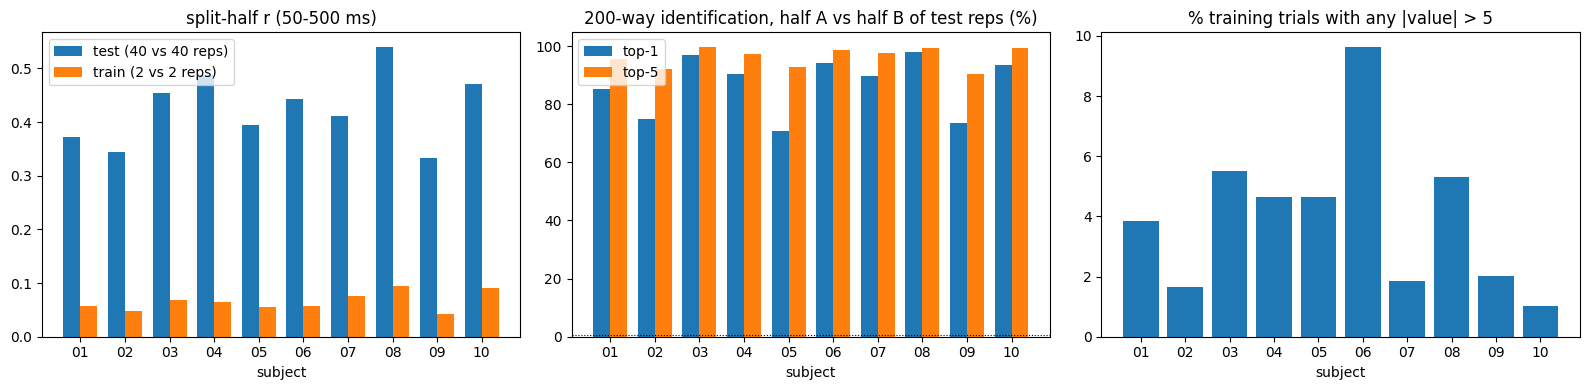

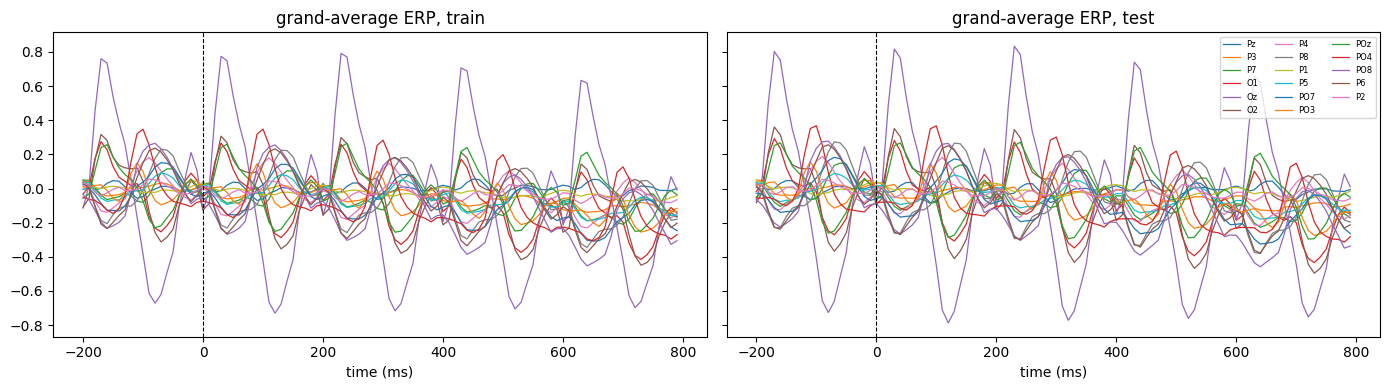

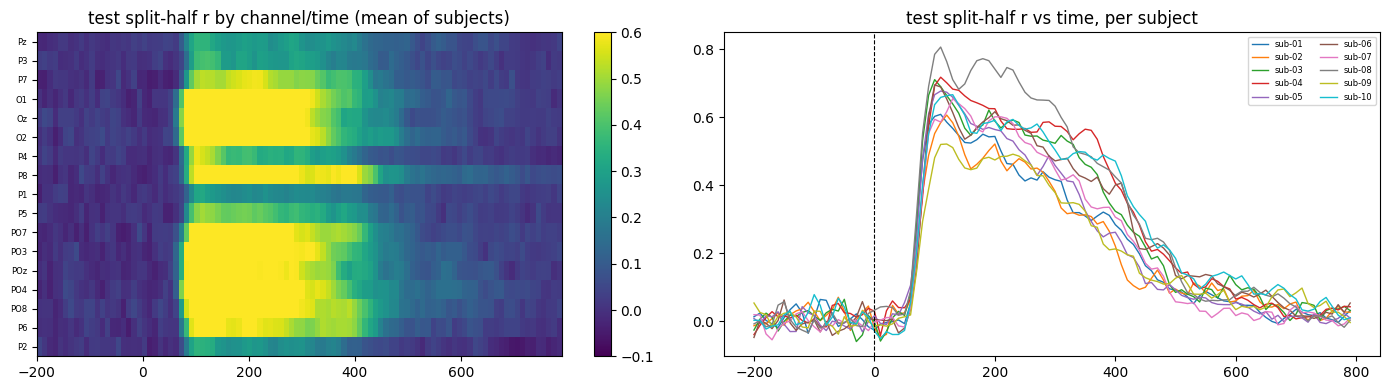

In [23]:
# ---- figures for the 17-channel data
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
x = np.arange(10); w = .38
ax[0].bar(x - w/2, [R17[s]['test_r'] for s in SUBJECTS], w, label='test (40 vs 40 reps)')
ax[0].bar(x + w/2, [R17[s]['train_r'] for s in SUBJECTS], w, label='train (2 vs 2 reps)')
ax[0].set_title('split-half r (50-500 ms)'); ax[0].legend()
ax[1].bar(x - w/2, [100 * R17[s]['test_top1'] for s in SUBJECTS], w, label='top-1'); ax[1].bar(x + w/2, [100 * R17[s]['test_top5'] for s in SUBJECTS], w, label='top-5')
ax[1].axhline(.5, c='k', ls=':', lw=.8); ax[1].set_title('200-way identification, half A vs half B of test reps (%)'); ax[1].legend()
ax[2].bar(x, [100 * R17[s]['train_frac_trials_gt5'] for s in SUBJECTS]); ax[2].set_title('% training trials with any |value| > 5')
for a in ax: a.set_xticks(x); a.set_xticklabels([s[-2:] for s in SUBJECTS]); a.set_xlabel('subject')
savefig('eeg17_per_subject.png')

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for k, nm in enumerate(['train', 'test']):
    G = np.mean([ERP17[nm][s] for s in SUBJECTS], 0)
    for c in range(17): ax[k].plot(TS * 1000, G[c], lw=.9, label=CH17[c])
    ax[k].axvline(0, c='k', ls='--', lw=.8); ax[k].set_title(f'grand-average ERP, {nm}'); ax[k].set_xlabel('time (ms)')
ax[1].legend(ncol=3, fontsize=6); savefig('eeg17_grand_erp.png')

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
Rm = np.mean([REL17['test'][s] for s in SUBJECTS], 0)
im = ax[0].imshow(Rm, aspect='auto', extent=[-200, 790, 16.5, -.5], vmin=-.1, vmax=.6); plt.colorbar(im, ax=ax[0])
ax[0].set_yticks(range(17)); ax[0].set_yticklabels(CH17, fontsize=6); ax[0].set_title('test split-half r by channel/time (mean of subjects)')
for s in SUBJECTS: ax[1].plot(TS * 1000, REL17['test'][s].mean(0), lw=1, label=s)
ax[1].axvline(0, c='k', ls='--', lw=.8); ax[1].set_title('test split-half r vs time, per subject'); ax[1].legend(ncol=2, fontsize=6)
savefig('eeg17_reliability.png')

### Conclusion, section 2 (17-channel EEG, all subjects) [TRAIN + TEST]
**What it showed**
- Every subject has the expected shapes, no NaNs, and the same time axis (-200 to 790 ms).
- **[TEST]** Split-half reliability (40 vs 40 reps) is 0.33-0.54; top-1 identification is 71-98%. Pre-stimulus reliability is about 0, so there is no leakage of the previous image in the baseline.
- **[TRAIN]** Reliability with 2 vs 2 reps is only 0.04-0.09: single trials are very noisy.
- **[TRAIN]** Outliers: 1-10% of training trials contain a value above 5 (sub-06 worst); extremes up to about -329 (sub-01) and +/-190 (sub-04).
- Grand-average ERP shows a clear 5 Hz rhythm (200 ms between images). Reliability starts at about 70 ms, peaks at 100-200 ms and is gone by about 600 ms.

**Why we need it**
- Tells us how noisy the signal is and that averaging repetitions matters.
- Shows clipping / robust scaling is required before training.
- Gives the subject ranking (08 best; 02, 05, 09 weakest), which sets expectations for per-subject results.

**Leakage:** the [TEST] numbers are descriptive. Use the [TRAIN] numbers (train reliability, outlier rates) for any decision, including the choice of pilot subjects.

## 3. EEG, 63-channel version, all subjects
Same measures, plus the direct comparison **17 posterior channels vs all 63 EEG channels vs the 46 other channels**, and a consistency check between the two versions of the data.

In [24]:
R63 = {}; REL63 = {}; M63_17_corr = {}; CH64 = None
for s in SUBJECTS:
    d = {}
    p = get_file(f'eeg/63ch/{s}/preprocessed_eeg_test.npy'); T = safe_load(p); release(p)
    X = T['preprocessed_eeg_data']; names = T['ch_names']; CH64 = names
    assert X.shape == (200, 80, 64, 100), X.shape
    if names[-1] != 'stim': print('WARNING: last channel is', names[-1])
    eeg_idx = [i for i, n in enumerate(names) if n != 'stim']
    idx17 = [names.index(c) for c in CH17]
    oth_idx = [i for i in eeg_idx if i not in idx17]
    A = X[:, 0::2].mean(1); B = X[:, 1::2].mean(1)
    r = splithalf(A, B)[:, WIN].mean(1); REL63[s] = r
    for nm, idx in [('p17', idx17), ('all63', eeg_idx), ('other46', oth_idx)]:
        d[f'test_top1_{nm}'], d[f'test_top5_{nm}'] = sym_ident(A, B, idx)
        d[f'test_r_{nm}'] = float(r[idx].mean())
    d['stim_test_r'] = float(r[names.index('stim')]); d['stim_test_std'] = float(X[:, :, names.index('stim')].std())
    # are the 17 channels in the 17ch file the same signal as the same channels in the 63ch file?
    a = M17[s].reshape(-1); b = X.mean(1)[:, idx17].reshape(-1)
    d['corr_17ch_file_vs_63ch_file'] = float(np.corrcoef(a, b)[0, 1])
    d['maxabsdiff_17ch_vs_63ch'] = float(np.abs(a - b).max())
    del X, A, B, T; gc.collect()
    R63[s] = d
    log(s, 'top1 p17=%.3f all63=%.3f other46=%.3f | corr(17ch file, 63ch file)=%.3f' %
        (d['test_top1_p17'], d['test_top1_all63'], d['test_top1_other46'], d['corr_17ch_file_vs_63ch_file']))
RES['eeg63_test'] = R63
display(pd.DataFrame(R63).T.round(3))

eeg/63ch/sub-01/preprocessed_eeg_test.np(…): reconstructing file:   0%|          |  0.00B /  819MB            

eeg/63ch/sub-01/preprocessed_eeg_test.np(…): downloading bytes:           |  0.00B            

[   761s] sub-01 top1 p17=0.863 all63=0.445 other46=0.043 | corr(17ch file, 63ch file)=0.981


eeg/63ch/sub-02/preprocessed_eeg_test.np(…): reconstructing file:   0%|          |  0.00B /  819MB            

eeg/63ch/sub-02/preprocessed_eeg_test.np(…): downloading bytes:           |  0.00B            

[   785s] sub-02 top1 p17=0.857 all63=0.350 other46=0.035 | corr(17ch file, 63ch file)=0.953


... (21 outputs left out)

eeg/63ch/sub-10/preprocessed_eeg_test.np(…): reconstructing file:   0%|          |  0.00B /  819MB            

eeg/63ch/sub-10/preprocessed_eeg_test.np(…): downloading bytes:           |  0.00B            

[   985s] sub-10 top1 p17=0.972 all63=0.667 other46=0.105 | corr(17ch file, 63ch file)=0.984


,test_top1_p17,test_top5_p17,test_r_p17,test_top1_all63,test_top5_all63,test_r_all63,test_top1_other46,test_top5_other46,test_r_other46,stim_test_r,stim_test_std,corr_17ch_file_vs_63ch_file,maxabsdiff_17ch_vs_63ch
sub-01,0.862,0.962,0.416,0.445,0.732,0.155,0.042,0.128,0.058,-0.009,1.027,0.981,0.368
sub-02,0.857,0.965,0.407,0.350,0.605,0.157,0.035,0.120,0.064,0.001,1.057,0.953,0.412
sub-03,0.988,1.000,0.510,0.718,0.905,0.201,0.082,0.235,0.086,-0.005,1.049,0.981,0.420
sub-04,0.938,0.985,0.524,0.600,0.850,0.229,0.115,0.275,0.120,-0.022,1.022,0.974,0.344
sub-05,0.835,0.968,0.434,0.358,0.620,0.169,0.040,0.115,0.070,0.015,1.059,0.978,0.455
sub-06,0.980,0.992,0.518,0.522,0.782,0.196,0.057,0.175,0.077,0.025,1.006,0.976,0.379
sub-07,0.938,0.990,0.470,0.617,0.878,0.180,0.040,0.140,0.073,0.012,1.078,0.982,0.638
sub-08,0.995,0.998,0.579,0.908,0.988,0.256,0.225,0.455,0.137,-0.047,1.048,0.980,0.452
sub-09,0.850,0.962,0.371,0.338,0.600,0.143,0.020,0.092,0.058,-0.022,1.001,0.970,0.332
sub-10,0.972,1.000,0.538,0.668,0.880,0.205,0.105,0.232,0.082,0.003,1.050,0.984,0.379


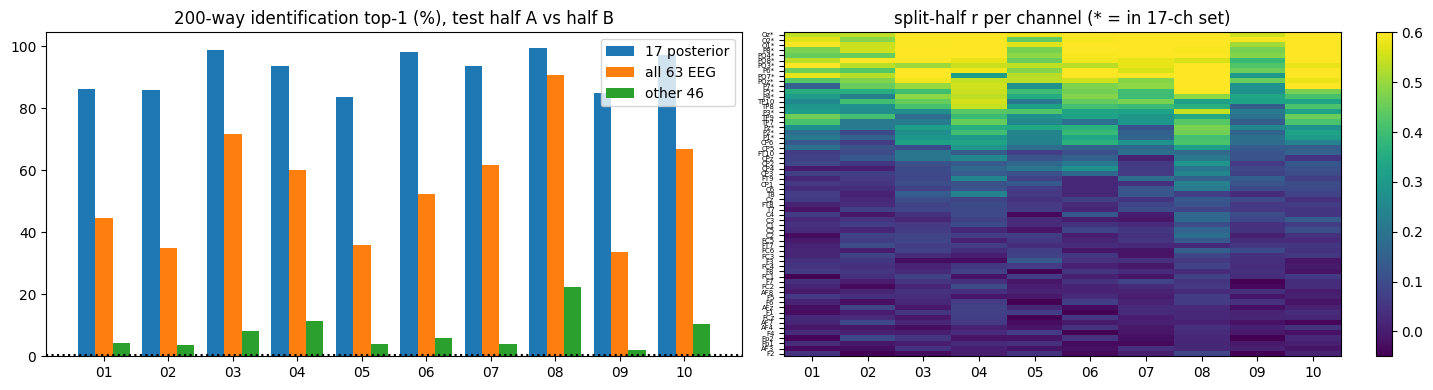

top-25 channels by mean split-half r: [('Oz', 0.604), ('O2', 0.595), ('O1', 0.589), ('P8', 0.582), ('PO4', 0.571), ('PO8', 0.565), ('PO3', 0.551), ('P6', 0.544), ('PO7', 0.528), ('POz', 0.528), ('P7', 0.445), ('P5', 0.427), ('P4', 0.403), ('TP10', 0.376), ('TP8', 0.356), ('P3', 0.345), ('TP9', 0.333), ('TP7', 0.302), ('Pz', 0.297), ('P2', 0.268), ('P1', 0.261), ('CP6', 0.257), ('CP5', 0.18), ('FT10', 0.133), ('CPz', 0.132)]


In [25]:
# ---- 17 vs 63 vs other-46 figure + per-channel reliability heatmap
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
w = .27; x = np.arange(10)
for k, (nm, lab) in enumerate([('p17', '17 posterior'), ('all63', 'all 63 EEG'), ('other46', 'other 46')]):
    ax[0].bar(x + (k - 1) * w, [100 * R63[s][f'test_top1_{nm}'] for s in SUBJECTS], w, label=lab)
ax[0].axhline(.5, c='k', ls=':'); ax[0].set_xticks(x); ax[0].set_xticklabels([s[-2:] for s in SUBJECTS])
ax[0].set_title('200-way identification top-1 (%), test half A vs half B'); ax[0].legend()
Rch = np.array([REL63[s] for s in SUBJECTS])                    # (10, 64)
order = np.argsort(-Rch.mean(0)); order = [i for i in order if CH64[i] != 'stim']
im = ax[1].imshow(Rch[:, order].T, aspect='auto', vmin=-.05, vmax=.6); plt.colorbar(im, ax=ax[1])
ax[1].set_yticks(range(len(order))); ax[1].set_yticklabels([CH64[i] + ('*' if CH64[i] in CH17 else '') for i in order], fontsize=5)
ax[1].set_xticks(range(10)); ax[1].set_xticklabels([s[-2:] for s in SUBJECTS]); ax[1].set_title('split-half r per channel (* = in 17-ch set)')
savefig('eeg63_vs_17.png')
RES['eeg63_channel_rank'] = [(CH64[i], float(Rch[:, i].mean())) for i in order[:25]]
print('top-25 channels by mean split-half r:', [(c, round(v, 3)) for c, v in RES['eeg63_channel_rank']])

In [26]:
# ---- 63-channel TRAINING data: outliers / reliability per channel (3.4 GB per subject in RAM)
R63tr = {}
if RUN_63CH_TRAIN:
    for s in SUBJECTS:
        p = get_file(f'eeg/63ch/{s}/preprocessed_eeg_training.npy'); T = safe_load(p); release(p)
        Y = T['preprocessed_eeg_data']; assert Y.shape == (16540, 4, 64, 100), Y.shape
        st = train_stats(Y)
        Aw = Y[:, 0:2][..., WIN].mean(1); Bw = Y[:, 2:4][..., WIN].mean(1)
        rr = splithalf(Aw, Bw).mean(1)
        idx17 = [CH64.index(c) for c in CH17]
        R63tr[s] = dict(nan=st['nan'], std=st['std'], min=st['min'], max=st['max'], frac_trials_gt5=st['frac_trials_gt5'],
                        frac_trials_gt10=st['frac_trials_gt10'], r_p17=float(rr[idx17].mean()),
                        r_other=float(np.mean([rr[i] for i in range(63) if i not in idx17])), r_stim=float(rr[CH64.index('stim')]),
                        ch_frac_gt5=st['ch_frac_gt5'].tolist())
        del Y, Aw, Bw, T; gc.collect()
        log(s, {k: round(v, 3) for k, v in R63tr[s].items() if not isinstance(v, list)})
    RES['eeg63_train'] = R63tr
    display(pd.DataFrame({s: {k: v for k, v in R63tr[s].items() if not isinstance(v, list)} for s in SUBJECTS}).T.round(3))
else:
    print('RUN_63CH_TRAIN = False -> skipped')

eeg/63ch/sub-01/preprocessed_eeg_trainin(…): reconstructing file:   0%|          |  0.00B / 3.39GB            

eeg/63ch/sub-01/preprocessed_eeg_trainin(…): downloading bytes:           |  0.00B            

[  1215s] sub-01 {'nan': 0, 'std': 0.86, 'min': -292.069, 'max': 200.225, 'frac_trials_gt5': 0.566, 'frac_trials_gt10': 0.397, 'r_p17': 0.066, 'r_other': 0.004, 'r_stim': 0.075}


eeg/63ch/sub-02/preprocessed_eeg_trainin(…): reconstructing file:   0%|          |  0.00B / 3.39GB            

eeg/63ch/sub-02/preprocessed_eeg_trainin(…): downloading bytes:           |  0.00B            

[  1287s] sub-02 {'nan': 0, 'std': 0.879, 'min': -96.753, 'max': 194.073, 'frac_trials_gt5': 0.626, 'frac_trials_gt10': 0.382, 'r_p17': 0.058, 'r_other': 0.008, 'r_stim': 0.081}


... (21 outputs left out)

eeg/63ch/sub-10/preprocessed_eeg_trainin(…): reconstructing file:   0%|          |  0.00B / 3.39GB            

eeg/63ch/sub-10/preprocessed_eeg_trainin(…): downloading bytes:           |  0.00B            

[  2285s] sub-10 {'nan': 0, 'std': 0.86, 'min': -79.15, 'max': 196.868, 'frac_trials_gt5': 0.612, 'frac_trials_gt10': 0.378, 'r_p17': 0.105, 'r_other': 0.007, 'r_stim': 0.076}


,nan,std,min,max,frac_trials_gt5,frac_trials_gt10,r_p17,r_other,r_stim
sub-01,0.0,0.860,-292.069,200.225,0.566,0.397,0.066,0.004,0.075
sub-02,0.0,0.879,-96.753,194.073,0.626,0.382,0.058,0.008,0.081
sub-03,0.0,0.817,-101.680,191.035,0.593,0.382,0.080,0.006,0.079
sub-04,0.0,0.894,-178.287,204.240,0.610,0.406,0.074,0.009,0.075
sub-05,0.0,0.958,-95.798,199.211,0.642,0.374,0.065,0.006,0.077
sub-06,0.0,1.043,-39.685,223.971,0.769,0.381,0.069,0.005,0.074
sub-07,0.0,0.811,-106.549,191.414,0.507,0.350,0.091,0.006,0.083
sub-08,0.0,0.895,-50.822,196.571,0.636,0.372,0.111,0.011,0.072
sub-09,0.0,0.801,-92.598,208.293,0.538,0.386,0.049,0.004,0.073
sub-10,0.0,0.860,-79.150,196.868,0.612,0.378,0.105,0.007,0.076


### Conclusion, section 3 (63-channel EEG) [TRAIN + TEST]
**What it showed**
- The "64 channels" are **63 EEG channels + a `stim` marker channel**.
- **[TEST]** With simple equal-weight correlation, the 17 posterior channels identify images far better than all 63 (92% vs 55% on average); the other 46 channels are near chance for most subjects.
- **[TEST]** The same 17 channels are more identifiable when taken from the 63-channel file (92%) than from the 17-channel file (87%). So the 63-channel files are not just a superset: their normalisation differs (hypothesis: MVNN depends on the channel set; not verified).
- **[TRAIN]** 51-77% of 63-channel training trials contain a value above 5 and 35-41% above 10, mostly from frontal channels (Fp1, Fp2, F7, F8: eye blinks). Training split-half reliability is 0.05-0.11 on the 17 posterior channels vs about 0.005-0.011 on the others.
- 17-channel and 63-channel files agree at correlation 0.95-0.98 but are not identical: do not mix them in one experiment.

**Why we need it**
- Decides which channels to feed the model, that frontal channels and `stim` must be dropped, and that clipping is mandatory.

**Leakage:** the claim "posterior channels carry the signal, frontal ones do not" is supported by [TRAIN] evidence too (reliability and outlier rates), so dropping frontal channels and `stim` is safe. The finer claim "17 vs 63 vs file version" rests on [TEST] only and must be confirmed by validation performance of the trained model.

## 4. Cross-subject analysis (relevant for leave-one-subject-out)
Do different people produce similar responses to the same 200 test images? Two views:
- **Cross-subject identification:** use subject *j*'s trial-averaged responses as the gallery and try to identify subject *i*'s responses (17 ch, no training, raw channels). The diagonal is the within-subject split-half value.
- **RDM agreement:** Spearman correlation between the 200x200 dissimilarity matrices of two subjects.

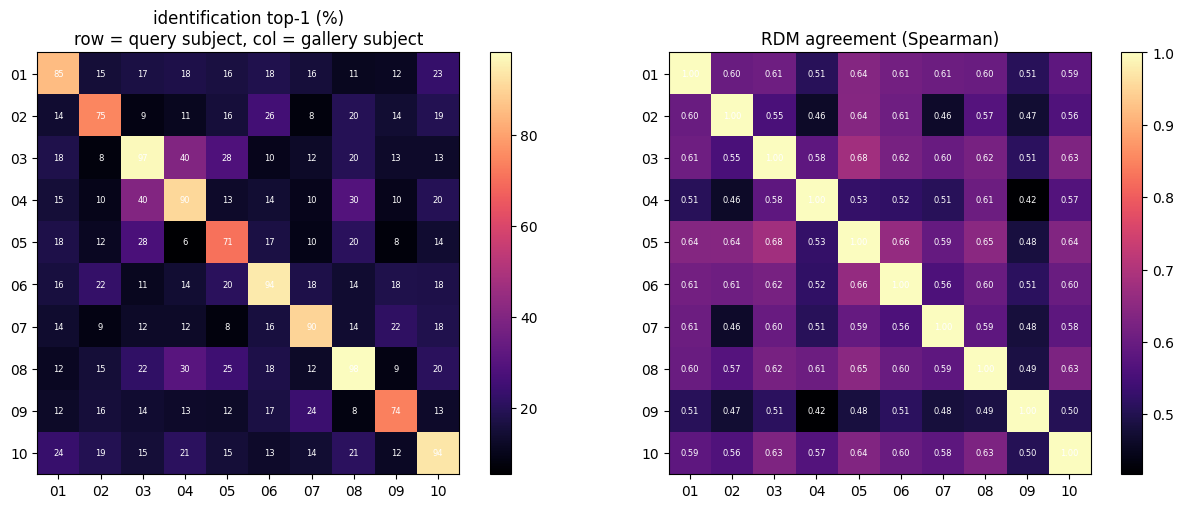

{
 "top1_offdiag_mean": 0.16255555555555554,
 "top5_offdiag_mean": 0.39138888888888884,
 "rdm_spearman_mean": 0.5681227883958961,
 "rdm_spearman_min": 0.4172104692334286,
 "per_subject_top1_as_query": {
  "sub-01": 0.16166666666666665,
  "sub-02": 0.15166666666666664,
  "sub-03": 0.1811111111111111,
  "sub-04": 0.1811111111111111,
  "sub-05": 0.14500000000000002,
  "sub-06": 0.16833333333333333,
  "sub-07": 0.13944444444444443,
  "sub-08": 0.1816666666666667,
  "sub-09": 0.1444444444444445,
  "sub-10": 0.1711111111111111
 },
 "per_subject_top1_as_gallery": {
  "sub-01": 0.15722222222222224,
  "sub-02": 0.13944444444444443,
  "sub-03": 0.18722222222222223,
  "sub-04": 0.18388888888888888,
  "sub-05": 0.17166666666666666,
  "sub-06": 0.16666666666666666,
  "sub-07": 0.13833333333333334,
  "sub-08": 0.175,
  "sub-09": 0.1305555555555556,
  "sub-10": 0.17555555555555558
 }
}


In [27]:
n = len(SUBJECTS)
X1 = np.zeros((n, n)); X5 = np.zeros((n, n))
for i, si in enumerate(SUBJECTS):
    for j, sj in enumerate(SUBJECTS):
        if i == j:
            X1[i, j], X5[i, j] = R17[si]['test_top1'], R17[si]['test_top5']
        else:
            X1[i, j], X5[i, j] = ident_acc(M17[si], M17[sj])
rdm = {s: 1 - np.corrcoef((M17[s] - M17[s].mean(0))[:, :, WIN].reshape(200, -1)) for s in SUBJECTS}
iu = np.triu_indices(200, 1)
C = spearmanr(np.array([rdm[s][iu] for s in SUBJECTS]).T).correlation
off = ~np.eye(n, dtype=bool)
RES['cross_subject'] = dict(top1_offdiag_mean=float(X1[off].mean()), top5_offdiag_mean=float(X5[off].mean()),
                            rdm_spearman_mean=float(C[off].mean()), rdm_spearman_min=float(C[off].min()),
                            per_subject_top1_as_query=dict(zip(SUBJECTS, [float(np.delete(X1[i], i).mean()) for i in range(n)])),
                            per_subject_top1_as_gallery=dict(zip(SUBJECTS, [float(np.delete(X1[:, j], j).mean()) for j in range(n)])))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, M, ttl, vmax in [(ax[0], X1 * 100, 'identification top-1 (%)\nrow = query subject, col = gallery subject', None), (ax[1], C, 'RDM agreement (Spearman)', 1)]:
    im = a.imshow(M, vmax=vmax, cmap='magma'); plt.colorbar(im, ax=a); a.set_title(ttl)
    a.set_xticks(range(n)); a.set_yticks(range(n)); a.set_xticklabels([s[-2:] for s in SUBJECTS]); a.set_yticklabels([s[-2:] for s in SUBJECTS])
    for i in range(n):
        for j in range(n): a.text(j, i, f'{M[i, j]:.0f}' if M is not C else f'{M[i, j]:.2f}', ha='center', va='center', fontsize=6, color='w')
savefig('cross_subject.png')
print(json.dumps(RES['cross_subject'], indent=1))

### Conclusion, section 4 (cross-subject) [TEST]
**What it showed**
- Without any training, one subject's averaged test responses identify another subject's responses with top-1 about 16% (top-5 about 39%); chance is 0.5%.
- The 200x200 dissimilarity matrices of different subjects correlate at about 0.57 (range 0.42-0.63).
- Subjects 02, 05, 07 and 09 are the hardest as the query.

**Why we need it**
- Shows that a stimulus-driven signal is shared across people, so "above chance on a new subject" (H2) is plausible.
- Sets expectations for which leave-one-subject-out folds will be hard.

**Leakage:** descriptive only (test EEG). Nothing here should tune the model. These numbers are not model accuracy and must not be compared with NICE's 6.2% for new subjects.

## 5. Evidence for the dataset split
(a) Does the evoked response strength differ between *concepts* (so a random concept split could be unbalanced)?
(b) How much does the luck of a random concept hold-out matter?
(c) Per-image repeatability distribution (some images may be much noisier than others).
Energies are z-scored within each subject, then averaged over subjects.

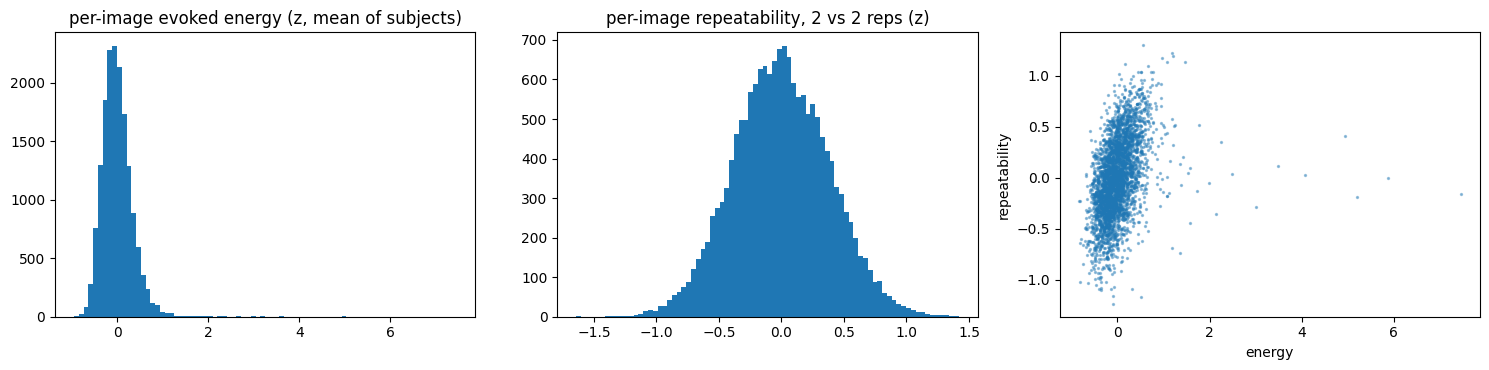

{
 "eta2_energy_by_concept": 0.2674155718752738,
 "eta2_energy_null": 0.0985816890419244,
 "eta2_repeat_by_concept": 0.2633988416229029,
 "eta2_repeat_null": 0.09924380263082712,
 "corr_energy_vs_repeat": 0.45313847047666755,
 "subject_corr_of_image_energy": 0.0366689093949318,
 "random_concept_holdout_sim": {
  "165": {
   "energy_diff_sd": 0.014762323325314276,
   "repeat_diff_sd": 0.015836756018020655
  },
  "330": {
   "energy_diff_sd": 0.011360379003484378,
   "repeat_diff_sd": 0.012314727642431909
  }
 }
}


In [28]:
def z(v): return (v - v.mean()) / v.std()
E = np.mean([z(IMG_ENERGY[s]) for s in SUBJECTS], 0)          # (16540,) evoked energy
H = np.mean([z(IMG_HALF_R[s]) for s in SUBJECTS], 0)          # (16540,) repeatability
ncon = CONCEPT_ID.max() + 1
def eta2(v, lab):
    m = v.mean(); cm = np.bincount(lab, v) / np.bincount(lab)
    return float((np.bincount(lab) * (cm - m) ** 2).sum() / ((v - m) ** 2).sum())
perm = np.random.default_rng(1).permutation(CONCEPT_ID)
RES['split'] = dict(eta2_energy_by_concept=eta2(E, CONCEPT_ID), eta2_energy_null=eta2(E, perm),
                    eta2_repeat_by_concept=eta2(H, CONCEPT_ID), eta2_repeat_null=eta2(H, perm),
                    corr_energy_vs_repeat=float(np.corrcoef(E, H)[0, 1]),
                    subject_corr_of_image_energy=float(np.corrcoef([z(IMG_ENERGY[s]) for s in SUBJECTS])[np.triu_indices(10, 1)].mean()))
ec = np.bincount(CONCEPT_ID, E) / np.bincount(CONCEPT_ID); hc = np.bincount(CONCEPT_ID, H) / np.bincount(CONCEPT_ID)
rng = np.random.default_rng(2); sim = {}
for K in [165, 330]:
    de, dh = [], []
    for _ in range(1000):
        h = rng.choice(ncon, K, replace=False); m = np.ones(ncon, bool); m[h] = False
        de.append(ec[h].mean() - ec[m].mean()); dh.append(hc[h].mean() - hc[m].mean())
    sim[K] = dict(energy_diff_sd=float(np.std(de)), repeat_diff_sd=float(np.std(dh)))
RES['split']['random_concept_holdout_sim'] = sim
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(E, 80); ax[0].set_title('per-image evoked energy (z, mean of subjects)')
ax[1].hist(H, 80); ax[1].set_title('per-image repeatability, 2 vs 2 reps (z)')
ax[2].scatter(E[::5], H[::5], s=2, alpha=.4); ax[2].set_xlabel('energy'); ax[2].set_ylabel('repeatability')
savefig('split_evidence.png')
print(json.dumps(RES['split'], indent=1))
# Do the per-image energies agree across subjects? (if yes, "noisy images" are image-driven, not subject-driven)

### Conclusion, section 5 (evidence for the split) [TRAIN]
**What it showed**
- Concept explains about 27% of the variance in per-image response strength (null from shuffled labels: about 10%); same for repeatability.
- A random hold-out of 165 or 330 concepts is balanced: group differences vary by only about 0.012-0.015 standard deviations.
- Per-image response strength is almost unrelated between subjects (r about 0.04): "noisy images" differ per subject.

**Why we need it**
- Justifies splitting validation **by concept** (10% of concepts, all their images), without stratification, and using the same validation concepts for all subjects and models.

**Leakage:** none. This section uses training data only, so it can drive decisions.

## 6. Summary (send this back)

In [29]:
rows = []
for s in SUBJECTS:
    r = dict(subject=s, test_r=R17[s]['test_r'], top1_17=R17[s]['test_top1'], top5_17=R17[s]['test_top5'],
             top1_63=R63[s]['test_top1_all63'], top1_other46=R63[s]['test_top1_other46'],
             trials_gt5_pct=100 * R17[s]['train_frac_trials_gt5'], trials_gt10_pct=100 * R17[s]['train_frac_trials_gt10'],
             train_min=R17[s]['train_min'], train_max=R17[s]['train_max'],
             xsubj_top1_as_query=RES['cross_subject']['per_subject_top1_as_query'][s])
    rows.append(r)
summary = pd.DataFrame(rows).set_index('subject')
display(summary.round(3))
RES['summary_table'] = summary.round(4).reset_index().to_dict('records')

def conv(o):
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
with open(os.path.join(OUT, 'results.json'), 'w') as f: json.dump(RES, f, indent=1, default=conv)
summary.to_csv(os.path.join(OUT, 'summary_table.csv'))
print('=' * 30, ' COPY FROM HERE ', '=' * 30)
print(summary.round(3).to_string())
print(json.dumps({k: RES[k] for k in ['images', 'cross_subject', 'split']}, indent=1, default=conv))
print('stim channel (sub-01..10) test split-half r:', [round(R63[s]['stim_test_r'], 3) for s in SUBJECTS])
print('17ch-file vs 63ch-file corr:', [round(R63[s]['corr_17ch_file_vs_63ch_file'], 3) for s in SUBJECTS])
print('=' * 30, '  TO HERE  ', '=' * 30)
import shutil
zp = shutil.make_archive(os.path.join(WORK, 'eda_out'), 'zip', OUT)
try:
    from google.colab import files; files.download(zp)
except Exception:
    print('saved', zp)

,test_r,top1_17,top5_17,top1_63,top1_other46,trials_gt5_pct,trials_gt10_pct,train_min,train_max,xsubj_top1_as_query
subject,,,,,,,,,,
sub-01,0.373,0.852,0.955,0.445,0.042,3.844,0.766,-328.758,85.146,0.162
sub-02,0.344,0.748,0.920,0.350,0.035,1.664,0.067,-67.812,19.348,0.152
sub-03,0.453,0.970,0.998,0.718,0.082,5.508,0.252,-29.875,27.811,0.181
sub-04,0.487,0.905,0.972,0.600,0.115,4.661,1.158,-180.341,191.111,0.181
sub-05,0.395,0.708,0.928,0.358,0.040,4.658,0.190,-32.337,32.339,0.145
sub-06,0.444,0.942,0.988,0.522,0.057,9.637,0.065,-42.755,26.406,0.168
sub-07,0.411,0.898,0.975,0.617,0.040,1.855,0.008,-15.176,8.454,0.139
sub-08,0.540,0.980,0.995,0.908,0.225,5.314,0.118,-16.346,14.887,0.182
sub-09,0.333,0.735,0.903,0.338,0.020,2.004,0.048,-19.074,17.861,0.144


==============================  COPY FROM HERE  ==============================
         test_r  top1_17  top5_17  top1_63  top1_other46  trials_gt5_pct  trials_gt10_pct  train_min  train_max  xsubj_top1_as_query
subject                                                                                                                             
sub-01    0.373    0.852    0.955    0.445         0.042           3.844            0.766   -328.758     85.146                0.162
sub-02    0.344    0.748    0.920    0.350         0.035           1.664            0.067    -67.812     19.348                0.152
sub-03    0.453    0.970    0.998    0.718         0.082           5.508            0.252    -29.875     27.811                0.181
sub-04    0.487    0.905    0.972    0.600         0.115           4.661            1.158   -180.341    191.111                0.181
sub-05    0.395    0.708    0.928    0.358         0.040           4.658            0.190    -32.337     32.339            

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Conclusion, section 6 (summary table)
One row per subject. Columns **test_r, top1_17, top5_17, top1_63, top1_other46, xsubj_top1_as_query** come from the test EEG [TEST]; **trials_gt5_pct, trials_gt10_pct, train_min, train_max** come from training data [TRAIN].
Use it to report data quality per subject. For picking pilot subjects, prefer a [TRAIN] ranking (train split-half reliability on the 63-channel data: best 08, 10, 07; weakest 09, 02, 01/05).

occipital               8 ch  e.g. ['O1', 'Oz', 'O2', 'PO7', 'PO3', 'POz']
parietal                9 ch  e.g. ['Pz', 'P3', 'P7', 'P4', 'P8', 'P1']
temporal               10 ch  e.g. ['FT9', 'T7', 'TP9', 'TP10', 'T8', 'FT10']
central                21 ch  e.g. ['FC5', 'FC1', 'C3', 'CP5', 'CP1', 'CP6']
frontal(rest)          15 ch  e.g. ['Fp1', 'F3', 'F7', 'F4', 'F8', 'Fp2']
17ch                   17 ch  e.g. ['Pz', 'P3', 'P7', 'O1', 'Oz', 'O2']
17ch+TP7/8/9/10        21 ch  e.g. ['Pz', 'P3', 'P7', 'O1', 'Oz', 'O2']
all63 minus frontal    48 ch  e.g. ['FT9', 'FC5', 'FC1', 'C3', 'T7', 'TP9']
all63                  63 ch  e.g. ['Fp1', 'F3', 'F7', 'FT9', 'FC5', 'FC1']


eeg/63ch/sub-01/preprocessed_eeg_test.np(…): reconstructing file:   0%|          |  0.00B /  819MB            

eeg/63ch/sub-01/preprocessed_eeg_test.np(…): downloading bytes:           |  0.00B            

[  2997s] sub-01 {'17ch': 86.2, '17ch+TP7/8/9/10': 86.2, 'all63 minus frontal': 63.7, 'all63': 44.5}


eeg/63ch/sub-02/preprocessed_eeg_test.np(…): reconstructing file:   0%|          |  0.00B /  819MB            

eeg/63ch/sub-02/preprocessed_eeg_test.np(…): downloading bytes:           |  0.00B            

... (21 outputs left out)

[  3122s] sub-09 {'17ch': 85.0, '17ch+TP7/8/9/10': 81.5, 'all63 minus frontal': 50.8, 'all63': 33.8}


eeg/63ch/sub-10/preprocessed_eeg_test.np(…): reconstructing file:   0%|          |  0.00B /  819MB            

eeg/63ch/sub-10/preprocessed_eeg_test.np(…): downloading bytes:           |  0.00B            

[  3133s] sub-10 {'17ch': 97.2, '17ch+TP7/8/9/10': 96.2, 'all63 minus frontal': 79.0, 'all63': 66.8}


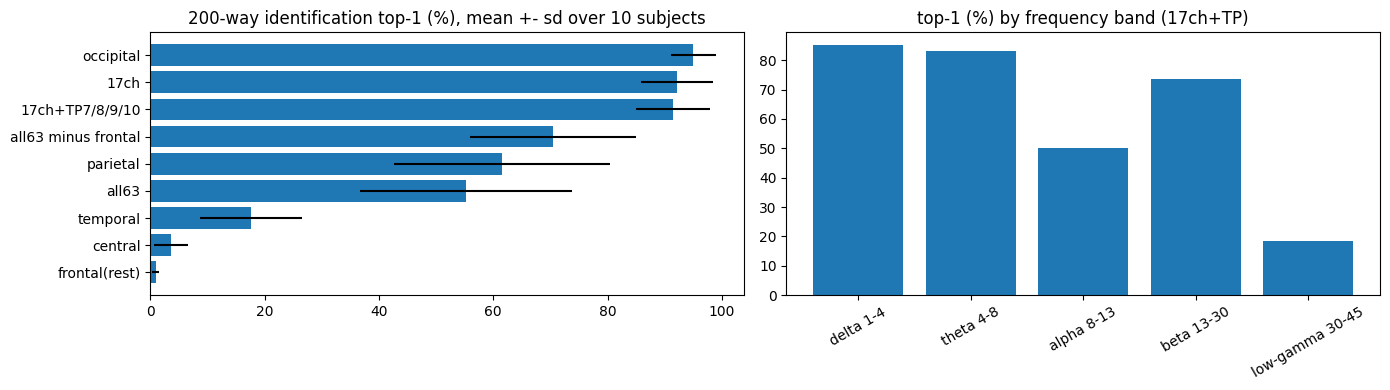

=========================  COPY FROM HERE  =========================
top-1 % by channel set (mean over subjects):
occipital              95.0
17ch                   92.2
17ch+TP7/8/9/10        91.4
all63 minus frontal    70.5
parietal               61.6
all63                  55.2
temporal               17.6
central                 3.6
frontal(rest)           0.9

per-subject top-1 %:
        17ch  17ch+TP7/8/9/10  all63 minus frontal  all63
sub-01  86.2             86.2                 63.7   44.5
sub-02  85.8             87.2                 59.0   35.0
sub-03  98.8             97.8                 82.5   71.8
sub-04  93.8             93.8                 77.8   60.0
sub-05  83.5             83.0                 49.5   35.8
sub-06  98.0             96.0                 71.8   52.2
sub-07  93.8             93.3                 76.2   61.7
sub-08  99.5             99.5                 94.5   90.8
sub-09  85.0             81.5                 50.8   33.8
sub-10  97.2             96.2   

In [30]:
# ===== BLOCK 1: channel groups, time-window sweep, frequency bands (63-ch TEST data, all subjects) =====
import re
from scipy.signal import butter, sosfiltfilt

names = CH64; ix = {n: i for i, n in enumerate(names)}
eeg = [n for n in names if n != 'stim']
def pick(rx): return [ix[n] for n in eeg if re.match(rx, n)]
G = {'occipital': pick(r'^(O|PO)'), 'parietal': pick(r'^P[0-9z]'),
     'temporal': pick(r'^(T|TP|FT)'), 'central': pick(r'^(C|CP|FC)')}
used = set(sum(G.values(), []))
G['frontal(rest)'] = [ix[n] for n in eeg if ix[n] not in used]
SETS = dict(G)
SETS['17ch'] = [ix[c] for c in CH17]
SETS['17ch+TP7/8/9/10'] = SETS['17ch'] + [ix[c] for c in ['TP7', 'TP8', 'TP9', 'TP10'] if c in ix]
SETS['all63 minus frontal'] = [ix[n] for n in eeg if ix[n] not in G['frontal(rest)']]
SETS['all63'] = [ix[n] for n in eeg]
for k, v in SETS.items(): print(f'{k:22s} {len(v):2d} ch  e.g. {[names[i] for i in v[:6]]}')

def ident_w(A, B, idx, mask):
    """200-way identification (top1, top5) between half A and half B, channels idx, time mask."""
    def one(X, Y):
        X = (X[:, idx] - X[:, idx].mean(0))[:, :, mask].reshape(len(X), -1)
        Y = (Y[:, idx] - Y[:, idx].mean(0))[:, :, mask].reshape(len(Y), -1)
        C = _norm_rows(X) @ _norm_rows(Y).T
        o = np.argsort(-C, 1)[:, :5]; g = np.arange(len(X))[:, None]
        return (o[:, :1] == g).mean(), (o == g).any(1).mean()
    a, b = one(A, B), one(B, A)
    return (a[0] + b[0]) / 2, (a[1] + b[1]) / 2

starts = [0, 50, 100, 200]; ends = [300, 400, 500, 600, 790]
bands = {'delta 1-4': (1, 4), 'theta 4-8': (4, 8), 'alpha 8-13': (8, 13), 'beta 13-30': (13, 30), 'low-gamma 30-45': (30, 45)}
big = SETS['17ch+TP7/8/9/10']
ABL, WINS, BANDS = {}, {}, {}
for s in SUBJECTS:
    p = get_file(f'eeg/63ch/{s}/preprocessed_eeg_test.npy'); T = safe_load(p); release(p)
    X = T['preprocessed_eeg_data']; assert T['ch_names'] == CH64
    A = X[:, 0::2].mean(1); B = X[:, 1::2].mean(1); del X, T; gc.collect()
    ABL[s] = {k: ident_w(A, B, v, WIN) for k, v in SETS.items()}
    WINS[s] = {(a, e): ident_w(A, B, big, (TS >= a / 1000) & (TS <= e / 1000)) for a in starts for e in ends}
    BANDS[s] = {}
    for bn, (lo, hi) in bands.items():
        sos = butter(3, [lo, hi], btype='band', fs=100, output='sos')
        BANDS[s][bn] = ident_w(sosfiltfilt(sos, A, axis=-1), sosfiltfilt(sos, B, axis=-1), big, WIN)
    log(s, {k: round(float(100 * ABL[s][k][0]), 1) for k in ('17ch', '17ch+TP7/8/9/10', 'all63 minus frontal', 'all63')})

tab = pd.DataFrame({k: [100 * ABL[s][k][0] for s in SUBJECTS] for k in SETS}, index=SUBJECTS)
wtab = pd.DataFrame([[np.mean([100 * WINS[s][(a, e)][0] for s in SUBJECTS]) for e in ends] for a in starts],
                    index=[f'start {a} ms' for a in starts], columns=[f'end {e} ms' for e in ends])
btab = pd.Series({bn: np.mean([100 * BANDS[s][bn][0] for s in SUBJECTS]) for bn in bands})
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
m = tab.mean().sort_values(); sd = tab.std()[m.index]
ax[0].barh(m.index, m.values, xerr=sd.values); ax[0].set_title('200-way identification top-1 (%), mean +- sd over 10 subjects')
ax[1].bar(btab.index, btab.values); ax[1].set_title('top-1 (%) by frequency band (17ch+TP)'); ax[1].tick_params(axis='x', rotation=30)
savefig('ablation_channels_bands.png')
RES['ablation'] = dict(top1_by_set=tab.mean().round(2).to_dict(), top1_by_set_sd=tab.std().round(2).to_dict(),
                       window_sweep_top1=wtab.round(2).to_dict(), bands_top1=btab.round(2).to_dict(),
                       n_channels={k: len(v) for k, v in SETS.items()})
print('=' * 25, ' COPY FROM HERE ', '=' * 25)
print('top-1 % by channel set (mean over subjects):'); print(tab.mean().round(1).sort_values(ascending=False).to_string())
print('\nper-subject top-1 %:'); print(tab[['17ch', '17ch+TP7/8/9/10', 'all63 minus frontal', 'all63']].round(1).to_string())
print('\nwindow sweep, top-1 % (set = 17ch+TP):'); print(wtab.round(1).to_string())
print('\nfrequency bands, top-1 %:'); print(btab.round(1).to_string())
print('=' * 25, '  TO HERE  ', '=' * 25)

### Conclusion, Block 1 (channel groups, time windows, frequency bands) [TEST]
**What it showed** (200-way identification, top-1, mean over 10 subjects)
- Channel sets: occipital 95.0%, 17 posterior 92.2%, 17+TP 91.4%, all 63 minus frontal 70.5%, parietal 61.6%, all 63 55.2%, temporal 17.6%, central 3.6%, frontal 0.9%.
- Time window (17+TP): best is start 50 ms with end 300-400 ms (about 94%); ending at 790 ms drops to about 77%; starting at 200 ms drops to about 78%.
- Bands: delta 85%, theta 83%, beta 74%, alpha 50%, low-gamma 18.5% (full band: 91%).

**Why we need it**
- Suggests where the stimulus information is (posterior channels, early window, low frequencies) and that the TP channels add nothing on this measure, unlike the temporal ablation in NICE.

**Leakage:** all numbers come from the test EEG, so they are **hypotheses, not decisions**. Safe decisions (backed by [TRAIN] evidence in section 3 and Block 2): drop frontal channels and `stim`; keep posterior channels. Still open: occipital-only vs 17 vs 17+TP, the exact window, and any band-pass. Decide them by validation-concept performance of the trained model, or re-run this block on training data (reps 0,1 vs 2,3 on random 200-image subsets). Note that the window 0-600 ms is also supported independently by the NICE paper (100-600 ms).

eeg/63ch/sub-01/preprocessed_eeg_trainin(…): reconstructing file:   0%|          |  0.00B / 3.39GB            

eeg/63ch/sub-01/preprocessed_eeg_trainin(…): downloading bytes:           |  0.00B            

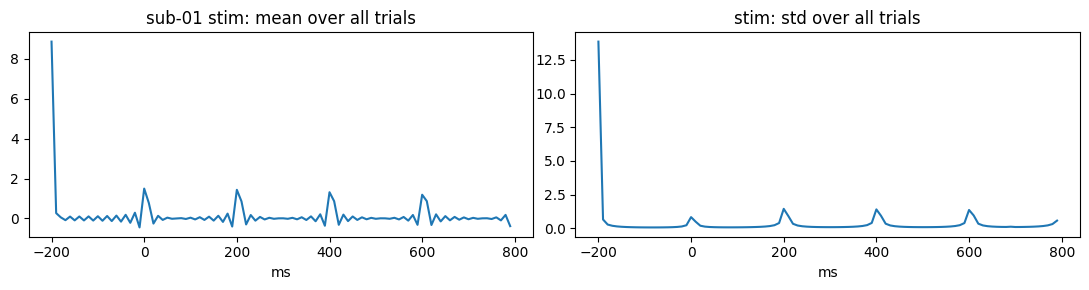

eeg/63ch/sub-08/preprocessed_eeg_trainin(…): reconstructing file:   0%|          |  0.00B / 3.39GB            

eeg/63ch/sub-08/preprocessed_eeg_trainin(…): downloading bytes:           |  0.00B            

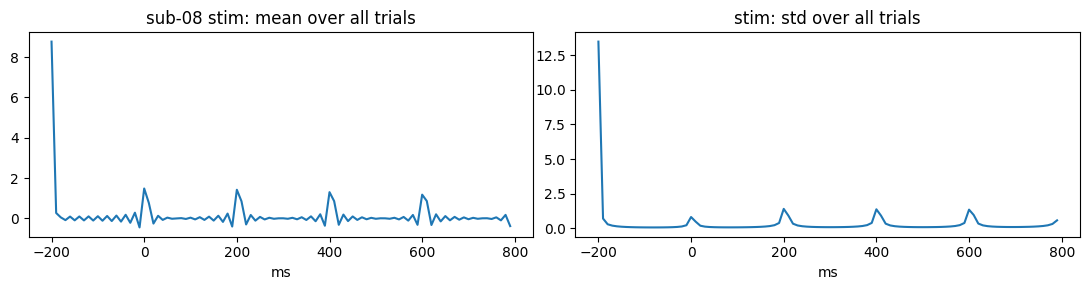

=========================  COPY FROM HERE  =========================
{
 "sub-01": {
  "n_unique_values_in_sample": 132400,
  "within_image_var / total_var": 0.986,
  "200-way top-1 % (chance 0.5)": {
   "stim": 0.6,
   "17ch": 3.15,
   "frontal": 0.6
  }
 },
 "sub-08": {
  "n_unique_values_in_sample": 132400,
  "within_image_var / total_var": 0.994,
  "200-way top-1 % (chance 0.5)": {
   "stim": 0.7,
   "17ch": 7.05,
   "frontal": 0.4
  }
 }
}
=========================   TO HERE   =========================


In [31]:
# ===== BLOCK 2: what is in the `stim` channel of the TRAINING data? (run BLOCK 1 first; needs ident_w and SETS) =====
def stim_check(s):
    p = get_file(f'eeg/63ch/{s}/preprocessed_eeg_training.npy'); T = safe_load(p); release(p)
    Y = T['preprocessed_eeg_data']; nm = T['ch_names']; si = nm.index('stim'); ixx = {n: i for i, n in enumerate(nm)}
    S = Y[:, :, si, :].copy()                                    # (images, 4 reps, 100 time points)
    out = {'n_unique_values_in_sample': int(len(np.unique(S[::50])))}
    # ~1.0 = repetitions of the same image are no more alike than different images (no image information)
    out['within_image_var / total_var'] = round(float(S.var(1, ddof=1).mean() / S.reshape(-1, S.shape[-1]).var(0).mean()), 3)
    rng = np.random.default_rng(0); res = {'stim': [], '17ch': [], 'frontal': []}
    chs = {'stim': [si], '17ch': [ixx[c] for c in CH17], 'frontal': SETS['frontal(rest)']}
    for _ in range(5):                                           # 5 random sets of 200 training images
        idx = rng.choice(len(Y), 200, replace=False)
        A = Y[idx][:, 0:2].mean(1); B = Y[idx][:, 2:4].mean(1)   # reps (0,1) vs reps (2,3)
        for k, ch in chs.items(): res[k].append(100 * ident_w(A, B, ch, WIN)[0])
    out['200-way top-1 % (chance 0.5)'] = {k: round(float(np.mean(v)), 2) for k, v in res.items()}
    fig, ax = plt.subplots(1, 2, figsize=(11, 3))
    ax[0].plot(TS * 1000, S.mean((0, 1))); ax[0].set_title(f'{s} stim: mean over all trials'); ax[0].set_xlabel('ms')
    ax[1].plot(TS * 1000, S.std((0, 1))); ax[1].set_title('stim: std over all trials'); ax[1].set_xlabel('ms')
    savefig(f'stim_{s}.png')
    del Y, T, S; gc.collect()
    return out

STIM = {s: stim_check(s) for s in ['sub-01', 'sub-08']}
RES['stim_train_check'] = STIM
print('=' * 25, ' COPY FROM HERE ', '=' * 25)
print(json.dumps(STIM, indent=1))
print('=' * 25, '  TO HERE  ', '=' * 25)

### Conclusion, Block 2 (`stim` channel in the training data) [TRAIN]
**What it showed** (sub-01 and sub-08 only)
- Identifying images from `stim` alone gives 0.6-0.7% top-1 (chance 0.5%), and repetitions of one image are no more alike than different images (variance ratio 0.99). So `stim` carries essentially no image information: **no label leakage through this channel**.
- For comparison, the 17 posterior channels reach 3.2% (sub-01) and 7.1% (sub-08) even with only 2 vs 2 repetitions on training data, and frontal channels stay at chance (0.4-0.6%).

**Why we need it**
- A marker channel could have leaked image identity into the model; this checks that it does not. It also gives a **[TRAIN]-only** confirmation that the posterior channels contain stimulus information while frontal ones do not.

**Limits:** only two subjects were checked, and the earlier weak training reliability of `stim` (about 0.075) is not fully explained. Drop `stim` anyway.

## What is decided and what is still open
| Decision | Status | Evidence |
|---|---|---|
| Split validation by concept (about 10% of concepts, fixed list for all subjects/models) | decided | [TRAIN] section 5, [IMAGES] section 1 |
| Test only at the end, on the 200 fixed test images | decided | proposal |
| Drop `stim` and frontal channels | decided | [TRAIN] sections 3 and Block 2 |
| Clip / robust-scale outliers | decided | [TRAIN] sections 2 and 3 |
| Average repetitions (4 per training image, 80 for test) | decided | NICE paper plus [TRAIN]/[TEST] reliability |
| Occipital-only vs 17 vs 17+TP vs 63 minus frontal | **open** | only [TEST] so far; decide on validation |
| Exact time window (about 0-600 ms) | **open**, 0-600 ms is a reasonable start | NICE paper; fine-tune on validation |
| Frequency band-pass | **open**, probably none | only [TEST] so far |
| 17-channel file vs 17 posterior channels of the 63-channel file | **open** | [TEST] hint: 63-channel file may be cleaner |
| Pilot subjects | pick from [TRAIN] ranking | e.g. 08, 04, 05, 09 |